###  Practice 2 - Notebook 1

# PCA with scikit-learn — Exercise 2

## Wine: How Many Components Keep 80% and 95% of the Variance?

This exercise follows Part 2 of the instructor's PCA notebook. We use the Wine dataset with 13 chemical features, standardize the features, fit PCA, and find the smallest number of components needed to retain 80% and 95% of the total variance.

**Question:** How many principal components keep 80% of the variance? How many keep 95%?

## Cell 1 — Import the Libraries

Import the tools needed to load the dataset, scale the features, fit PCA, and plot explained variance.

In [1]:
# General tools for data handling and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset loading and feature scaling
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

# Principal Component Analysis
from sklearn.decomposition import PCA

## Cell 2 — Load the Wine Dataset

Load the 178 wine samples and their 13 chemical measurements. The class labels are kept separate because PCA is unsupervised and does not need the labels.

In [2]:
# Load the Wine dataset as a DataFrame
wine = load_wine(as_frame=True)
X = wine.data
y = wine.target

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
display(X.head())

Dataset shape: (178, 13)
Number of features: 13


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## Cell 3 — Standardize the Features

The Wine features use different measurement scales. Apply `StandardScaler` before PCA so that features with large numerical ranges do not dominate the principal components.

In [3]:
# Standardize every feature to have approximately zero mean and unit variance
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)
print("Overall scaled mean (approximately 0):", round(X_scaled.mean(), 4))
print("Overall scaled standard deviation (approximately 1):", round(X_scaled.std(), 4))

Scaled data shape: (178, 13)
Overall scaled mean (approximately 0): -0.0
Overall scaled standard deviation (approximately 1): 1.0


## Cell 4 — Fit PCA Using All 13 Components

Fit PCA to the standardized data. `explained_variance_ratio_` tells us the share of variance explained by each component. The cumulative sum tells us how much variance is retained when we keep the first *n* components.

In [4]:
# Fit PCA without reducing the number of components yet
pca_full = PCA()
pca_full.fit(X_scaled)

# Calculate each component's share and the cumulative share of variance
ratios = pca_full.explained_variance_ratio_
cumulative = np.cumsum(ratios)

variance_table = pd.DataFrame({
    "component": np.arange(1, len(ratios) + 1),
    "explained_variance_ratio": ratios,
    "cumulative_variance": cumulative
})

# Display the variance explained by each component and by all components up to it
display(variance_table.round(4))

,component,explained_variance_ratio,cumulative_variance
0,1,0.3620,0.3620
1,2,0.1921,0.5541
2,3,0.1112,0.6653
3,4,0.0707,0.7360
4,5,0.0656,0.8016
5,6,0.0494,0.8510
6,7,0.0424,0.8934
7,8,0.0268,0.9202
8,9,0.0222,0.9424
9,10,0.0193,0.9617


## Cell 5 — Find the Minimum Number of Components

For each target, find the first cumulative variance value that reaches or exceeds the target. That component count is the minimum needed to retain the requested share of variance.

In [5]:
# Find the smallest component count that reaches each variance target
n_80 = np.argmax(cumulative >= 0.80) + 1
n_95 = np.argmax(cumulative >= 0.95) + 1

print(f"Components needed for 80% variance: {n_80}")
print(f"Variance retained with {n_80} components: {cumulative[n_80 - 1]:.2%}")
print()
print(f"Components needed for 95% variance: {n_95}")
print(f"Variance retained with {n_95} components: {cumulative[n_95 - 1]:.2%}")

Components needed for 80% variance: 5
Variance retained with 5 components: 80.16%

Components needed for 95% variance: 10
Variance retained with 10 components: 96.17%


## Cell 6 — Plot the Explained Variance

The left plot shows each component's individual contribution. The right plot shows the cumulative variance and marks the 80% and 95% targets.

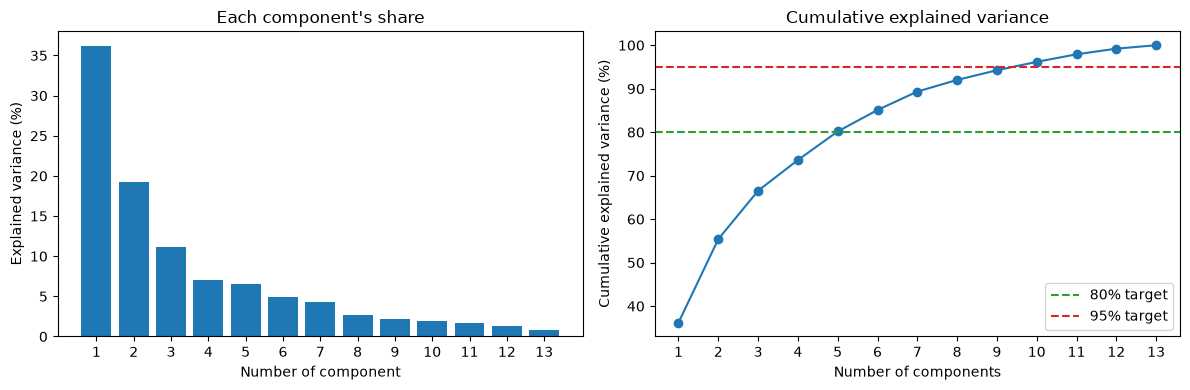

In [6]:
# Create side-by-side plots for individual and cumulative explained variance
n = np.arange(1, len(ratios) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(n, ratios * 100)
axes[0].set_xlabel("Number of component")
axes[0].set_ylabel("Explained variance (%)")
axes[0].set_title("Each component's share")
axes[0].set_xticks(n)

axes[1].plot(n, cumulative * 100, marker="o")
axes[1].axhline(80, color="tab:green", linestyle="--", label="80% target")
axes[1].axhline(95, color="tab:red", linestyle="--", label="95% target")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative explained variance (%)")
axes[1].set_title("Cumulative explained variance")
axes[1].set_xticks(n)
axes[1].legend()

plt.tight_layout()
plt.show()

## Final Answer

- **80% of the variance:** keep the smallest number of components reported in Cell 5.
- **95% of the variance:** keep the smallest number of components reported in Cell 5.

The cumulative variance increases as more components are kept. The 95% target requires at least as many components as the 80% target, because retaining more variance requires preserving more principal components.